# 3D FEA: plate and shields beside a tube with measured temperatures

This is a finite-element version of issues [#1](https://github.com/andrewgsavage/radiation/issues/1)
and [#3](https://github.com/andrewgsavage/radiation/issues/3), driven by the measured tube
temperatures in [`astral_temps.csv`](astral_temps.csv). The model is in [`fea3d.py`](fea3d.py)
and is built on scikit-fem.

**Model**
- Each sheet (plate, shields) is a solid hexahedral mesh, with conduction in x, y and z.
- The tube runs from x = 100 to 300 mm, split into 40 segments, each held at the measured
  temperature. Readings are interpolated and mirrored about x = 200 mm.
- The sheets are 140 × 220 mm, centred on the tube (x = 130–270 mm, mid-height).
- Every quad on a sheet's broad faces is a gray-diffuse radiation surface. It exchanges
  radiation with the tube segments, the facing sheet, and a black room at 25 °C.
- Churchill–Chu natural convection acts on the two faces open to room air. Still air conducts
  heat across the gaps between sheets.
- Hot air rising off the tube is ignored.
- Material defaults: tube ε 0.8; plate 1 mm carbon steel, ε 0.8; shields 0.5 mm stainless,
  ε 0.2, mid-planes evenly spaced in the 10 mm gap.
- With no plate, the outermost shield's mid-plane sits 10 mm from the tube.

Rerun `python run_fea_cases.py` (about 10 minutes) to regenerate `fea_results.json`, which
this notebook reads.

In [1]:
import json
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm, colors

import radiation as rad
import radiation3d as r3
import fea3d

C = 273.15
s = rad.Setup()
profiles = r3.load_tube_profiles("astral_temps.csv")
results = json.load(open("fea_results.json", encoding="utf-8"))
plt.rcParams.update({"figure.dpi": 110})

## Tube temperature profiles

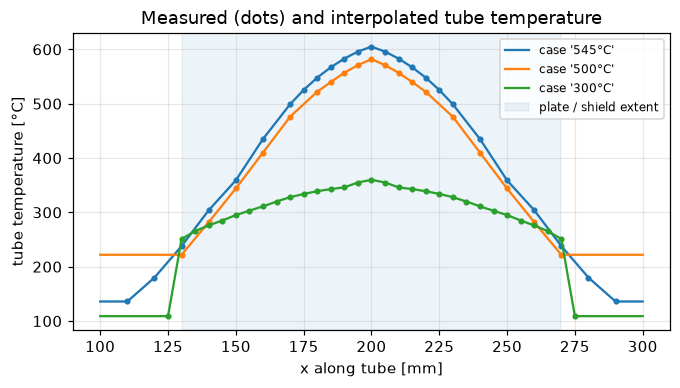

In [2]:
xs = np.linspace(0.100, 0.300, 201)
fig, ax = plt.subplots(figsize=(7, 3.5))
for name, prof in profiles.items():
    line, = ax.plot(xs * 1e3, r3.tube_temperature(prof, xs) - C, label=f"case '{name}'")
    ax.plot(prof[0] * 1e3, prof[1] - C, "o", ms=3, color=line.get_color())
ax.axvspan(130, 270, color="tab:blue", alpha=0.08, label="plate / shield extent")
ax.set_xlabel("x along tube [mm]"); ax.set_ylabel("tube temperature [°C]"); ax.grid(alpha=0.3)
ax.set_title("Measured (dots) and interpolated tube temperature"); ax.legend(fontsize=8)
plt.show()

## Validation and mesh convergence

With a uniform 650 °C tube spanning the plate, the FEA reproduces the x–z patch model in
[`radiation3d.py`](radiation3d.py):

In [3]:
flat = (np.array([0.0, 0.14]), np.array([s.T_tube] * 2))
kw = dict(tube_x=(0.0, 0.14), plate_x0=0.0, n_segments=28)
for n in (0, 1):
    f = fea3d.solve_fea(s, flat, n, **kw)
    p = r3.solve3d(s, flat, n, **kw)
    print(f"{n} shield(s): FEA plate peak {f.T_plate_max - C:6.1f} °C, mean {f.T_plate_mean - C:6.1f} °C | "
          f"patch model peak {p.T_plate_max - C:6.1f} °C, mean {p.T_plate_mean - C:6.1f} °C")

0 shield(s): FEA plate peak  192.7 °C, mean  119.1 °C | patch model peak  192.5 °C, mean  119.0 °C


1 shield(s): FEA plate peak   62.5 °C, mean   52.6 °C | patch model peak   61.8 °C, mean   52.1 °C


In [4]:
print("mesh (x × z × thickness) | shields | plate peak | plate mean | run time")
for row in results["convergence"]:
    print(f"   {row['n_x']:3d} × {row['n_z']:3d} × {row['n_y']}          |    {row['shields']}    | "
          f"{row['peak']:7.1f} °C | {row['mean']:7.1f} °C | {row['seconds']:5.0f} s")

mesh (x × z × thickness) | shields | plate peak | plate mean | run time
    10 ×  15 × 2          |    0    |   129.1 °C |    76.9 °C |     2 s
    10 ×  15 × 2          |    1    |    45.3 °C |    39.6 °C |     2 s
    20 ×  30 × 2          |    0    |   130.0 °C |    76.8 °C |     7 s
    20 ×  30 × 2          |    1    |    45.5 °C |    39.6 °C |     9 s
    20 ×  30 × 4          |    0    |   130.0 °C |    76.8 °C |     8 s
    20 ×  30 × 4          |    1    |    45.5 °C |    39.6 °C |    12 s
    30 ×  45 × 2          |    0    |   130.1 °C |    76.8 °C |    20 s
    30 ×  45 × 2          |    1    |    45.6 °C |    39.6 °C |    26 s
    40 ×  60 × 2          |    0    |   130.2 °C |    76.8 °C |    39 s


## Results

In [5]:
print(f"{'case':8s} | {'layout':18s} | outer peak | outer mean | hottest sheet | patch-model peak")
for row in results["cases"]:
    layout = (f"plate + {row['shields']} shield" if row["plate"] else f"no plate, {row['shields']} shield") + ("s" if row["shields"] != 1 else "")
    flag = "  > 150" if row["peak"] >= 150 else ""
    print(f"{row['profile']:8s} | {layout:18s} | {row['peak']:7.0f} °C | {row['mean']:7.0f} °C | "
          f"{row['hottest_sheet']:9.0f} °C  | {row['patch_peak']:9.0f} °C{flag}")

case     | layout             | outer peak | outer mean | hottest sheet | patch-model peak
545°C    | plate + 0 shields  |     130 °C |      77 °C |       130 °C  |       130 °C
545°C    | plate + 1 shield   |      46 °C |      40 °C |       116 °C  |        45 °C
545°C    | plate + 2 shields  |      42 °C |      38 °C |       122 °C  |        41 °C
545°C    | no plate, 1 shield |      99 °C |      50 °C |        99 °C  |        98 °C
545°C    | no plate, 2 shields |      62 °C |      44 °C |       122 °C  |        61 °C
545°C    | no plate, 3 shields |      53 °C |      43 °C |       125 °C  |        51 °C
500°C    | plate + 0 shields  |     120 °C |      72 °C |       120 °C  |       119 °C
500°C    | plate + 1 shield   |      43 °C |      38 °C |       106 °C  |        43 °C
500°C    | plate + 2 shields  |      40 °C |      37 °C |       112 °C  |        39 °C
500°C    | no plate, 1 shield |      92 °C |      48 °C |        92 °C  |        91 °C
500°C    | no plate, 2 shields |     

In [6]:
print("Shields needed to keep the outermost sheet's peak below 150 °C")
for name in profiles:
    for plate in (True, False):
        rows = [r for r in results["cases"] if r["profile"] == name and r["plate"] == plate]
        ok = [r["shields"] for r in rows if r["peak"] < 150]
        need = min(ok) if ok else f"> {max(r['shields'] for r in rows)}"
        print(f"  case '{name}', {'with plate' if plate else 'no plate  '}: {need}")

Shields needed to keep the outermost sheet's peak below 150 °C
  case '545°C', with plate: 0
  case '545°C', no plate  : 1
  case '500°C', with plate: 0
  case '500°C', no plate  : 1
  case '300°C', with plate: 0
  case '300°C', no plate  : 1


## 3D temperature contours

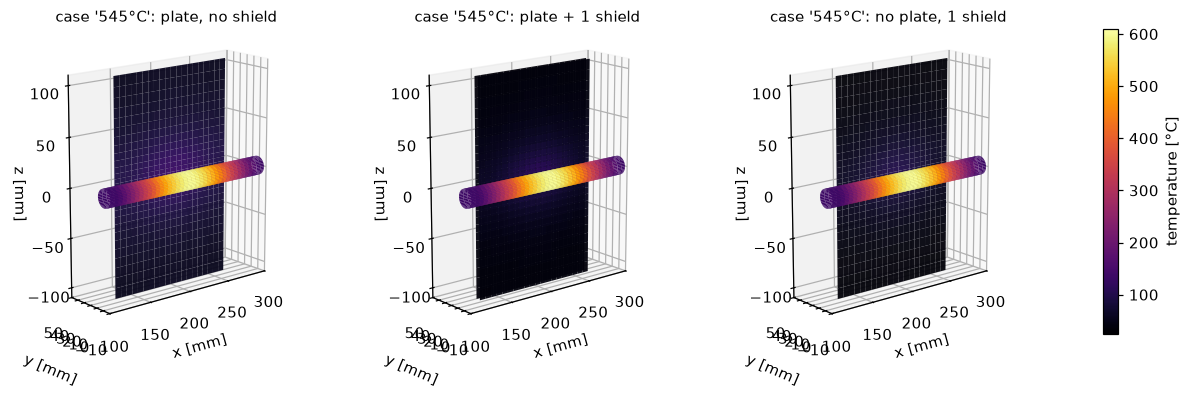

In [7]:
def draw(ax, res, norm, title):
    r_mm = s.tube_od / 2 * 1e3
    X, Z = np.meshgrid(res.x * 1e3, res.z * 1e3, indexing="ij")
    for y, T in zip(res.y, res.T):
        Tf = T[:, 0, :] - C  # tube-side face
        ax.plot_surface(X, np.full_like(X, y[0] * 1e3), Z, facecolors=cm.inferno(norm(Tf)),
                        rstride=1, cstride=1, shade=False, linewidth=0, alpha=0.95)
    phi = np.linspace(0, 2 * np.pi, 40)
    TX, TP = np.meshgrid(res.tube_x * 1e3, phi, indexing="ij")
    Tt = np.repeat(res.tube_T[:, None] - C, len(phi), axis=1)
    ax.plot_surface(TX, r_mm * np.cos(TP), r_mm * np.sin(TP), facecolors=cm.inferno(norm(Tt)),
                    shade=False, linewidth=0)
    ax.set_xlabel("x [mm]"); ax.set_ylabel("y [mm]"); ax.set_zlabel("z [mm]")
    ax.set_box_aspect((200, 60, 220)); ax.view_init(elev=15, azim=-130)
    ax.set_xlim(100, 300); ax.set_ylim(-10, 50); ax.set_zlim(-110, 110)
    ax.set_title(title, fontsize=10)

prof = profiles["545°C"]
cases = [(0, True, "plate, no shield"), (1, True, "plate + 1 shield"), (1, False, "no plate, 1 shield")]
solved = [fea3d.solve_fea(s, prof, n, plate=p) for n, p, _ in cases]
norm = colors.Normalize(25, 610)
fig = plt.figure(figsize=(15, 6))
for i, (res, (_, _, title)) in enumerate(zip(solved, cases)):
    draw(fig.add_subplot(1, 3, i + 1, projection="3d"), res, norm, f"case '545°C': {title}")
fig.colorbar(cm.ScalarMappable(norm=norm, cmap="inferno"), ax=fig.axes, shrink=0.6, label="temperature [°C]")
plt.show()

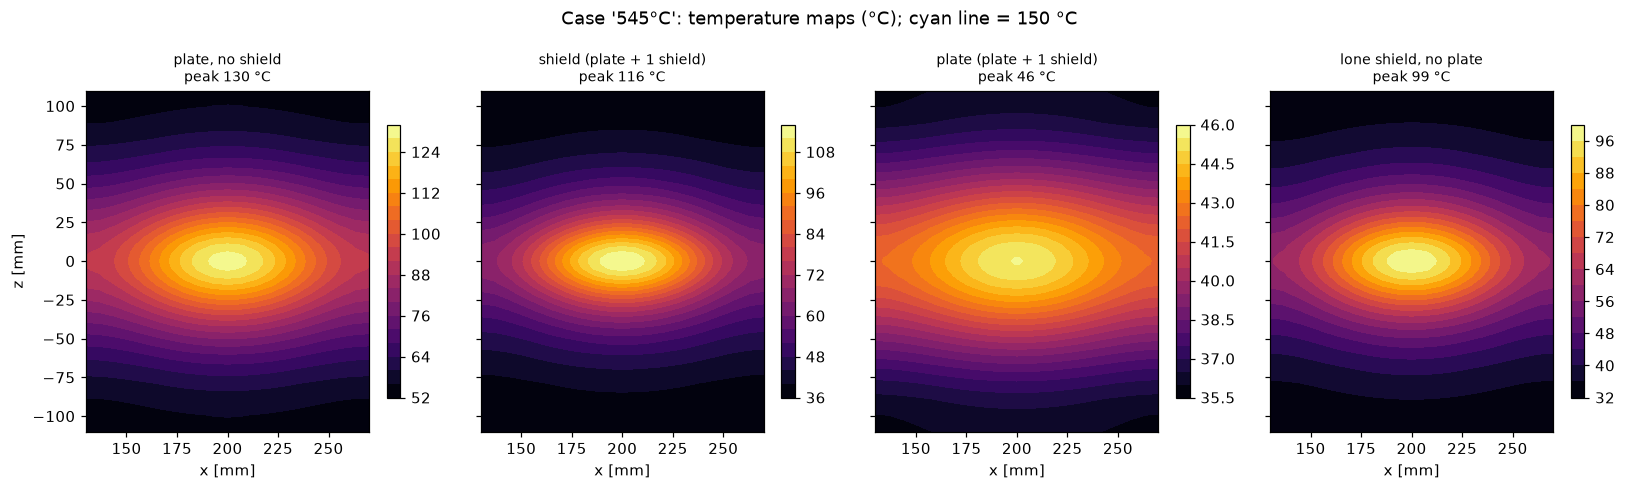

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(15, 4.5), sharey=True)
panels = [(solved[0], -1, "plate, no shield"), (solved[1], 0, "shield (plate + 1 shield)"),
          (solved[1], -1, "plate (plate + 1 shield)"), (solved[2], -1, "lone shield, no plate")]
for ax, (res, k, title) in zip(axes, panels):
    T = res.T[k][:, -1, :] - C if k == -1 else res.T[k][:, 0, :] - C
    cs = ax.contourf(res.x * 1e3, res.z * 1e3, T.T, levels=20, cmap="inferno")
    ax.contour(res.x * 1e3, res.z * 1e3, T.T, levels=[150], colors="cyan", linewidths=1.5)
    fig.colorbar(cs, ax=ax, shrink=0.8)
    ax.set_title(f"{title}\npeak {T.max():.0f} °C", fontsize=9); ax.set_xlabel("x [mm]")
axes[0].set_ylabel("z [mm]")
fig.suptitle("Case '545°C': temperature maps (°C); cyan line = 150 °C")
plt.tight_layout(); plt.show()

## Notes

- The FEA uses the same view factors and boundary physics as the patch model, but solves
  conduction in solid elements, through the thickness, and carries the sheet thickness in the
  gap geometry. The two models agree to within a few degrees, so the thin-sheet
  simplification in the earlier models holds.
- These are the base-case assumptions. A warmer enclosure (issue #4), hot air rising off the
  tube, or oxidised shields (higher ε) all raise the temperatures.